# 04 · Baseline features & a first honest model

We build a model table and compare models under a **time-based split**:
- **Train:** fights from 2010‑03 (when corner order becomes trustworthy) to 2023. Earlier fights still feed fighter *history*.
- **Test:** fights from 2024‑01‑01 to 2026‑10 (what "predicting the future" really looks like, and mostly fights the original files never had)

Models:
1. Always pick Red (the baseline)
2. Logistic regression on the **minimum features**
3. Logistic regression on **minimum + history** features
4. Two **deliberately leaky** models, to show why the earlier warnings matter

In [1]:
import os, sys
from pathlib import Path
# Run from the project root no matter where Jupyter was started.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from ufc.features import add_history, build_model_table, swap_corners, check_no_lookahead, MIN_FEATURES, HIST_FEATURES, Clipper
from ufc.viz import use_style, SERIES, INK_2
use_style()

fights = pd.read_parquet("data/processed/fights.parquet")
ff = add_history(pd.read_parquet("data/processed/fighter_fights.parquet"))
check_no_lookahead(ff)          # brute-force spot check: features only use earlier fights
t = build_model_table(fights, ff)
t.to_parquet("data/processed/model_table.parquet", index=False)
print(t.shape)

(7502, 87)


In [2]:
SPLIT = pd.Timestamp("2024-01-01")
train, test = t[t.date < SPLIT], t[t.date >= SPLIT]
print(f"train {len(train)} fights ({train.date.min():%Y}–{train.date.max():%Y}), red win {train.red_win.mean():.1%}")
print(f"test  {len(test)} fights ({test.date.min():%Y}–{test.date.max():%Y}), red win {test.red_win.mean():.1%}")

train 6027 fights (2010–2023), red win 58.4%
test  1475 fights (2024–2026), red win 55.1%


## Corner-swap augmentation
If we train on raw rows, the model can learn "red usually wins" without learning anything about the fighters.
The fix: duplicate each training fight with the corners swapped (target flipped), and add a `red_corner` column (+1 original, −1 swapped).
Now the fighter-difference coefficients must explain the outcome **symmetrically**, and the red-corner effect is isolated in one coefficient we can read off.

In [3]:
def augment(df):
    a = df.assign(red_corner=1)
    b = swap_corners(df).assign(red_corner=-1)
    return pd.concat([a, b], ignore_index=True)

def make_model():
    # clip extreme values (fighters with 1 short fight have silly rates), impute + missing flags, scale
    return make_pipeline(Clipper(0.01, 0.99), SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(), LogisticRegression(C=0.5, max_iter=2000))

def evaluate(name, p, y):
    return {"model": name, "accuracy": accuracy_score(y, p > 0.5), "log_loss": log_loss(y, p),
            "roc_auc": roc_auc_score(y, p) if 0 < p.std() else 0.5}

results = []
p_red = np.full(len(test), train.red_win.mean())
results.append(evaluate("1. always pick Red", p_red, test.red_win))

In [4]:
FLAGS = ["r_debut", "b_debut", "reach_missing"]
feature_sets = {
    "2. minimum features":     [f + "_diff" for f in MIN_FEATURES] + FLAGS + ["red_corner"],
    "3. minimum + history":    [f + "_diff" for f in MIN_FEATURES + HIST_FEATURES] + FLAGS + ["red_corner"],
}
aug_train = augment(train)
test_x = test.assign(red_corner=1)
models = {}
for name, cols in feature_sets.items():
    m = make_model().fit(aug_train[cols], aug_train.red_win)
    models[name] = (m, cols)
    results.append(evaluate(name, m.predict_proba(test_x[cols])[:, 1], test.red_win))
pd.DataFrame(results).set_index("model").round(3)

,accuracy,log_loss,roc_auc
model,,,
1. always pick Red,0.551,0.690,0.500
2. minimum features,0.616,0.653,0.658
3. minimum + history,0.642,0.640,0.684


**How to read these metrics:**
- **Accuracy:** % of fights picked correctly. Intuitive, but crude.
- **Log loss** (lower is better): punishes confident wrong predictions. This matters most once we compare against betting odds, where *calibrated probabilities* are the whole game.
- **ROC AUC:** how well the model *ranks* who is more likely to win. 0.5 = random. "Always Red" gets 0.5 because it gives every fight the same probability.

## What the model learned

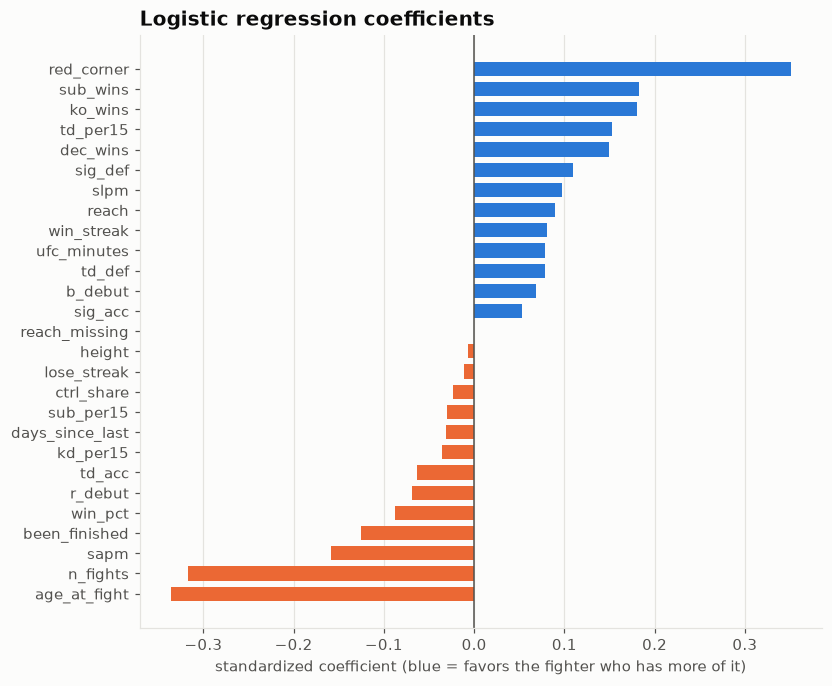

In [5]:
m, cols = models["3. minimum + history"]
coef = pd.Series(m[-1].coef_[0][:len(cols)], index=cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh([c.replace("_diff", "") for c in coef.index], coef.values,
        color=[SERIES[0] if v > 0 else SERIES[1] for v in coef.values], height=0.7)
ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("standardized coefficient (blue = favors the fighter who has more of it)")
ax.set_title("Logistic regression coefficients")
plt.show()

## The leakage demo
Two models that look amazing but are useless for prediction:
- **Leaky A (in-fight stats):** uses strikes, takedowns, and control time *from the fight itself*. That's not prediction, it's describing the result.
- **Leaky B (career snapshot):** uses each fighter's career record and averages *as of today*, which is exactly what a fighter-stats page shows. Every 2024 fight "knows" how both careers turned out afterwards.

In [6]:
inf = fights.set_index("fight_id")
for c in ["kd", "sig_str", "td", "ctrl_sec", "sub_att"]:
    t[f"leakA_{c}"] = t.fight_id.map(inf[f"r_{c}"] - inf[f"b_{c}"])
# "career totals as of today": every fighter's whole UFC record, including fights AFTER the one we predict
g = ff.groupby("fighter")
snap = pd.DataFrame({"wins": g.is_W.sum(), "losses": g.is_L.sum(),
                     "slpm": g.sig_str.sum() / g.minutes.sum(), "sapm": g.opp_sig_str.sum() / g.minutes.sum(),
                     "td_per15": 15 * g.td.sum() / g.minutes.sum()})
snap["win_pct"] = snap.wins / (snap.wins + snap.losses)
for c in snap.columns:
    t[f"leakB_{c}"] = t.r_fighter.map(snap[c]) - t.b_fighter.map(snap[c])
train, test = t[t.date < SPLIT], t[t.date >= SPLIT]

for name, prefix in [("4a. LEAKY: in-fight stats", "leakA_"), ("4b. LEAKY: career snapshot", "leakB_")]:
    cols = [c for c in t.columns if c.startswith(prefix)]
    m = make_model().fit(train[cols], train.red_win)
    results.append(evaluate(name, m.predict_proba(test[cols])[:, 1], test.red_win))

res = pd.DataFrame(results).set_index("model").round(3)
res

,accuracy,log_loss,roc_auc
model,,,
1. always pick Red,0.551,0.690,0.500
2. minimum features,0.616,0.653,0.658
3. minimum + history,0.642,0.640,0.684
4a. LEAKY: in-fight stats,0.884,0.284,0.952
4b. LEAKY: career snapshot,0.825,0.388,0.906


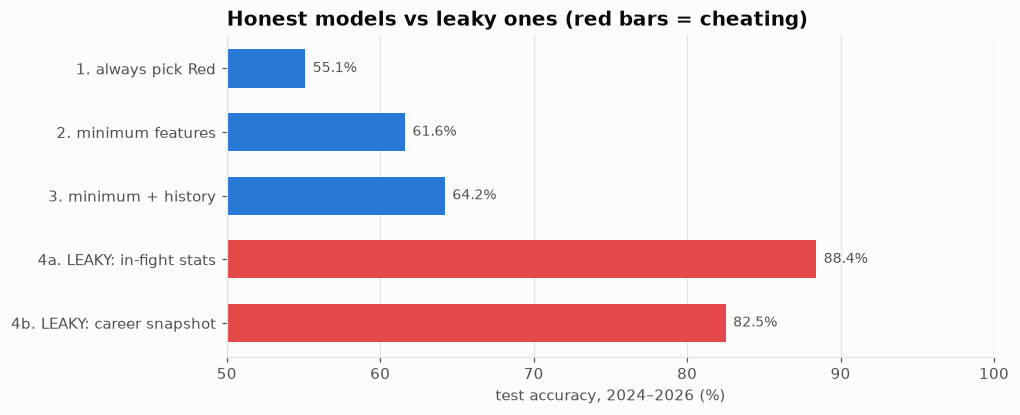

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [SERIES[7] if "LEAKY" in i else SERIES[0] for i in res.index]
ax.barh(res.index[::-1], res.accuracy[::-1] * 100, color=colors[::-1], height=0.6)
for i, v in enumerate(res.accuracy[::-1]):
    ax.text(v * 100 + 0.5, i, f"{v:.1%}", va="center", color=INK_2, fontsize=9)
ax.set_xlim(50, 100); ax.set_xlabel("test accuracy, 2024–2026 (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Honest models vs leaky ones (red bars = cheating)")
plt.show()

## Takeaways
- The leaky models score very high because they're **reading the answer**. Remember this the next time you see a "95% accurate UFC predictor" online.
- Honest models: **55.1% → 61.6% → 64.2%** (always Red → minimum features → + history). Every step beats the baseline on accuracy, log loss, and AUC. (The older `.venv` gives 64.3%, which is one fight out of 1,475, from numerical differences between library versions.)
- Red-corner advantage is shrinking: 58.4% in training years, 55.1% in 2024–2026. A model that leaned on "pick Red" would quietly get worse over time. That's **concept drift**, and it's why time-based splits matter.
- For context, betting favorites win roughly 65–70% of UFC fights. Closing that gap is the modeling phase's job.
- An earlier version of this notebook trained on pre-2010 fights, where red was always the winner. Removing those 1,290 rows *improved* every honest model: clean labels beat more data.

## Ideas for the modeling phase (advanced)
1. **Elo / Glicko ratings:** a rating that updates after each fight and accounts for *who* you beat. Usually the single strongest feature.
2. **Shrinkage (empirical Bayes):** pull rate stats of fighters with few fights toward the division average instead of clipping.
3. **Recency-weighted history:** exponentially weighted averages (recent fights count more), plus "last 3 fights" form.
4. **Opponent-adjusted stats:** strikes landed relative to what that opponent usually absorbs.
5. **Gradient boosting** (LightGBM / XGBoost) to capture interactions (e.g. age matters more at heavyweight).
6. **Calibration curves + walk-forward validation** (retrain each year, predict the next).
7. **SHAP** values to explain individual predictions on the website.